In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("✅ All Libraries Imported!")
print("Pandas:", pd.__version__)

✅ All Libraries Imported!
Pandas: 2.3.3


In [3]:
df = pd.read_csv(r"C:\Users\acer\Downloads\housing.csv.zip")
print("✅ housing.csv Loaded!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

✅ housing.csv Loaded!
Shape: (20640, 10)
Columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


In [4]:
df.head(10)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
5,-122.25,37.85,52.0,919.0,213.0,413.0,193.0,4.0368,269700.0,NEAR BAY
6,-122.25,37.84,52.0,2535.0,489.0,1094.0,514.0,3.6591,299200.0,NEAR BAY
7,-122.25,37.84,52.0,3104.0,687.0,1157.0,647.0,3.1200,241400.0,NEAR BAY
8,-122.26,37.84,42.0,2555.0,665.0,1206.0,595.0,2.0804,226700.0,NEAR BAY
9,-122.25,37.84,52.0,3549.0,707.0,1551.0,714.0,3.6912,261100.0,NEAR BAY


In [5]:
df.tail(5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [7]:
df.describe().round(2)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.00,20640.00,20640.00,20640.00,20433.00,20640.00,20640.00,20640.00,20640.00
mean,-119.57,35.63,28.64,2635.76,537.87,1425.48,499.54,3.87,206855.82
std,2.00,2.14,12.59,2181.62,421.39,1132.46,382.33,1.90,115395.62
min,-124.35,32.54,1.00,2.00,1.00,3.00,1.00,0.50,14999.00
25%,-121.80,33.93,18.00,1447.75,296.00,787.00,280.00,2.56,119600.00
50%,-118.49,34.26,29.00,2127.00,435.00,1166.00,409.00,3.53,179700.00
75%,-118.01,37.71,37.00,3148.00,647.00,1725.00,605.00,4.74,264725.00
max,-114.31,41.95,52.00,39320.00,6445.00,35682.00,6082.00,15.00,500001.00


In [9]:
print("--- MISSING VALUES ---")
print(df.isnull().sum())
print("\nTotal Missing Values:", df.isnull().sum().sum())
print("\nNote: total_bedrooms has 207 missing values - we will fill them with median")

--- MISSING VALUES ---
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Total Missing Values: 207

Note: total_bedrooms has 207 missing values - we will fill them with median


In [10]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [11]:
print("--- OCEAN_PROXIMITY CATEGORIES ---")
print(df['ocean_proximity'].value_counts())

--- OCEAN_PROXIMITY CATEGORIES ---
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


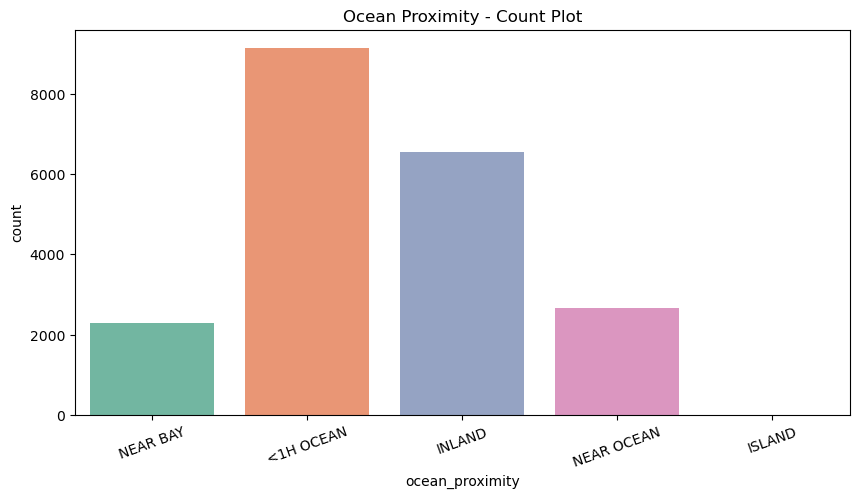

In [12]:
plt.figure(figsize=(10,5))
sns.countplot(data=df, x='ocean_proximity', palette='Set2')
plt.title('Ocean Proximity - Count Plot')
plt.xticks(rotation=20)
plt.show()

In [13]:
print("--- CORRELATION WITH median_house_value ---")
print(df.corr(numeric_only=True)['median_house_value'].sort_values(ascending=False))

--- CORRELATION WITH median_house_value ---
median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


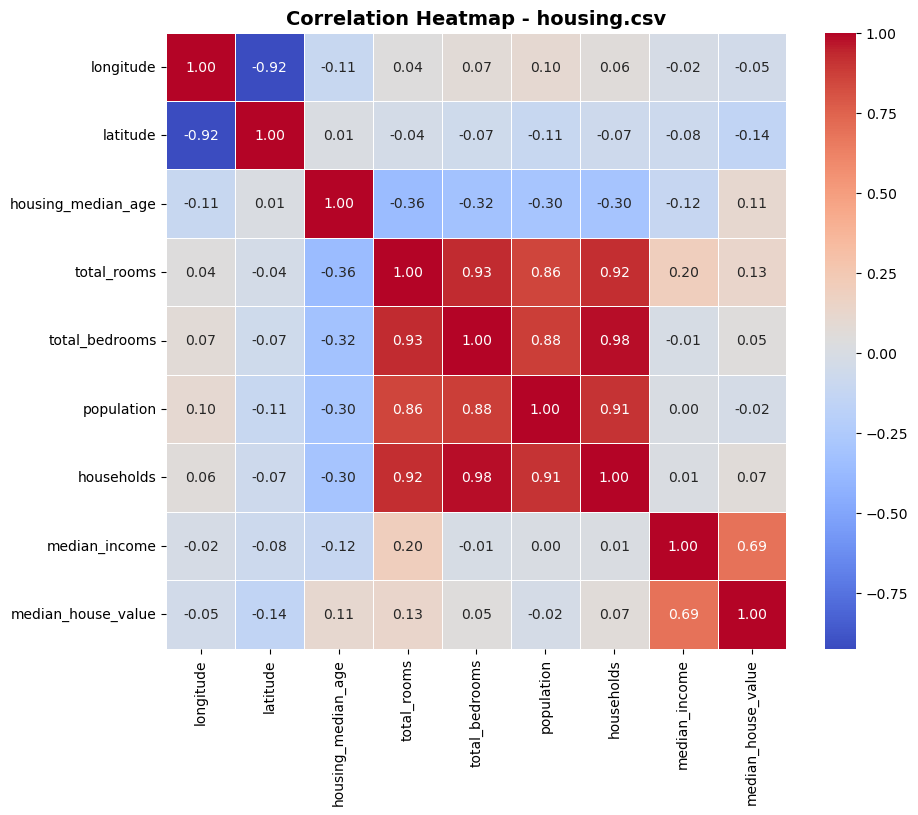

In [14]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap - housing.csv', fontsize=14, fontweight='bold')
plt.show()

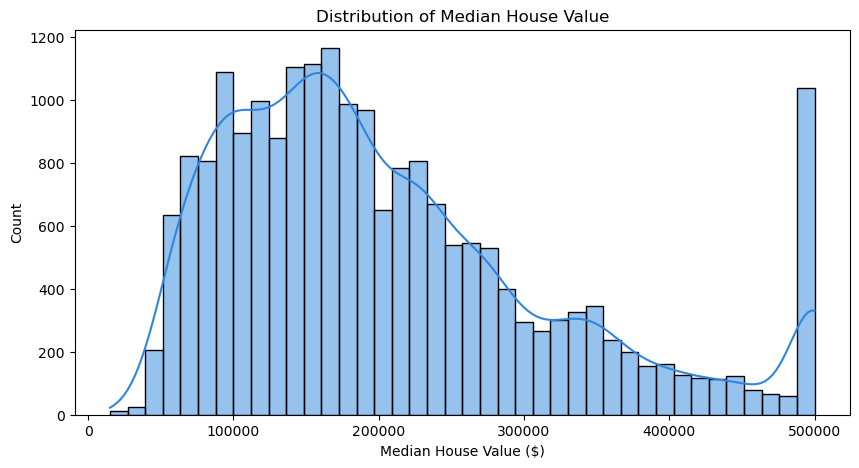

In [15]:
plt.figure(figsize=(10,5))
sns.histplot(df['median_house_value'], bins=40, kde=True, color='#2E86DE')
plt.title('Distribution of Median House Value')
plt.xlabel('Median House Value ($)')
plt.ylabel('Count')
plt.show()

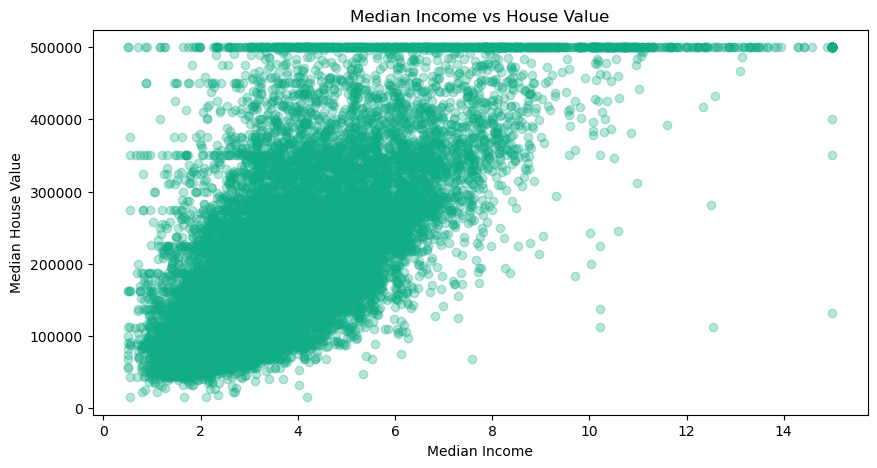

In [16]:
plt.figure(figsize=(10,5))
plt.scatter(df['median_income'], df['median_house_value'], alpha=0.3, color='#10AC84')
plt.title('Median Income vs House Value')
plt.xlabel('Median Income')
plt.ylabel('Median House Value')
plt.show()

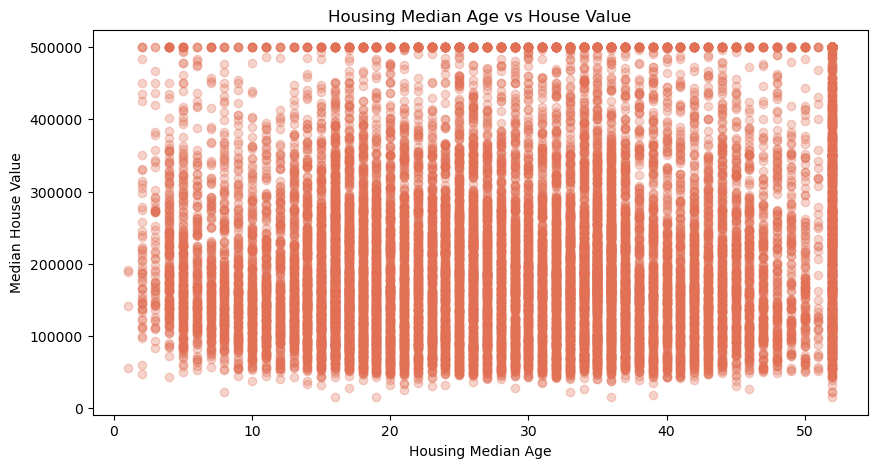

In [17]:
plt.figure(figsize=(10,5))
plt.scatter(df['housing_median_age'], df['median_house_value'], alpha=0.3, color='#E17055')
plt.title('Housing Median Age vs House Value')
plt.xlabel('Housing Median Age')
plt.ylabel('Median House Value')
plt.show()

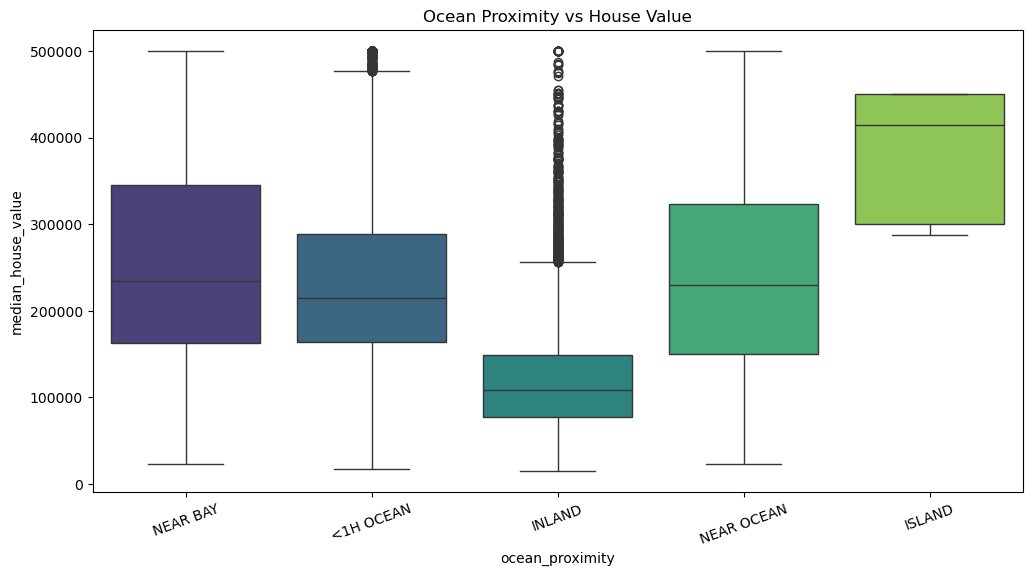

In [18]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x='ocean_proximity', y='median_house_value', palette='viridis')
plt.title('Ocean Proximity vs House Value')
plt.xticks(rotation=20)
plt.show()

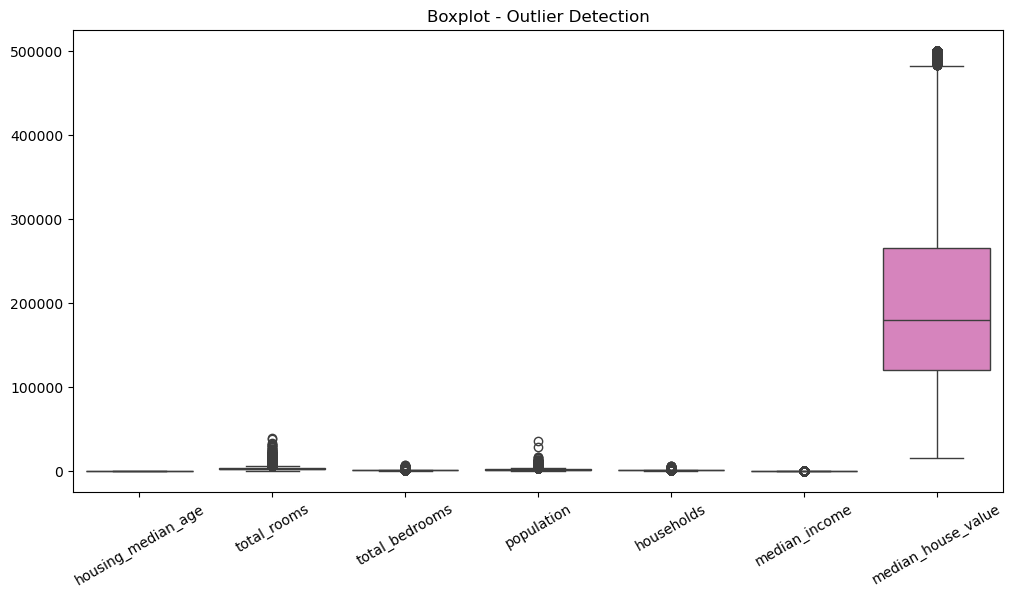

In [19]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df[['housing_median_age','total_rooms','total_bedrooms','population','households','median_income','median_house_value']])
plt.title('Boxplot - Outlier Detection')
plt.xticks(rotation=30)
plt.show()


In [20]:
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
df['population_per_household'] = df['population'] / df['households']
print("✅ 3 New Features Created!")
print(df[['rooms_per_household','bedrooms_per_room','population_per_household']].head())

✅ 3 New Features Created!
   rooms_per_household  bedrooms_per_room  population_per_household
0             6.984127           0.146591                  2.555556
1             6.238137           0.155797                  2.109842
2             8.288136           0.129516                  2.802260
3             5.817352           0.184458                  2.547945
4             6.281853           0.172096                  2.181467


In [21]:
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']
print("Features:", X.columns.tolist())
print("X Shape:", X.shape, "| y Shape:", y.shape)


Features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']
X Shape: (20640, 12) | y Shape: (20640,)


In [22]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16512, 12)
X_test: (4128, 12)
y_train: (16512,)
y_test: (4128,)


In [23]:
numeric_features = X.select_dtypes(include=['int64','float64']).columns.tolist()
categorical_features = ['ocean_proximity']
print("Numeric Features:", numeric_features)
print("Categorical Features:", categorical_features)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])
print("✅ Preprocessor Ready!")

Numeric Features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']
Categorical Features: ['ocean_proximity']
✅ Preprocessor Ready!


In [24]:
lr_model = Pipeline(steps=[('preprocessor', preprocessor),
                           ('model', LinearRegression())])
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)
print("✅ Linear Regression Trained Successfully!")

✅ Linear Regression Trained Successfully!


In [26]:
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)
print("--- LINEAR REGRESSION RESULTS ---")
print(f"MAE  : {mae_lr:.2f}")
print(f"RMSE : {rmse_lr:.2f}")
print(f"R2 Score : {r2_lr:.4f}")
print(f"Accuracy : {r2_lr*100:.2f}%")


--- LINEAR REGRESSION RESULTS ---
MAE  : 49645.49
RMSE : 69127.04
R2 Score : 0.6353
Accuracy : 63.53%


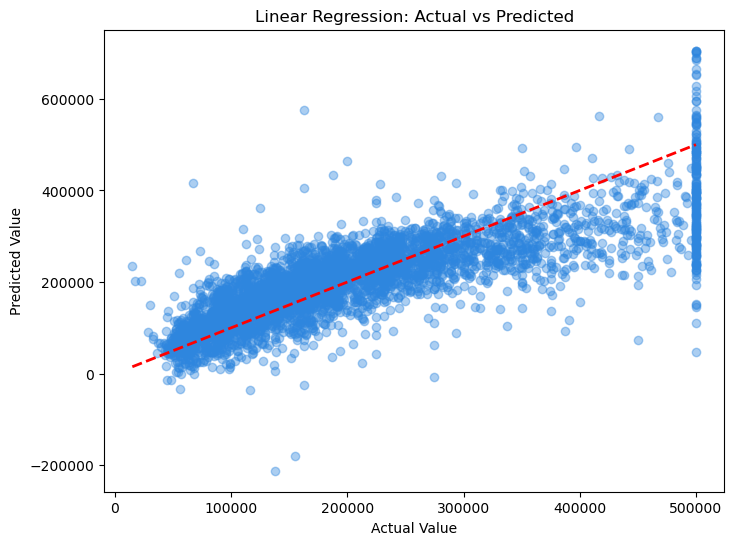

In [27]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_lr, alpha=0.4, color='#2E86DE')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Linear Regression: Actual vs Predicted')
plt.xlabel('Actual Value')
plt.ylabel('Predicted Value')
plt.show()

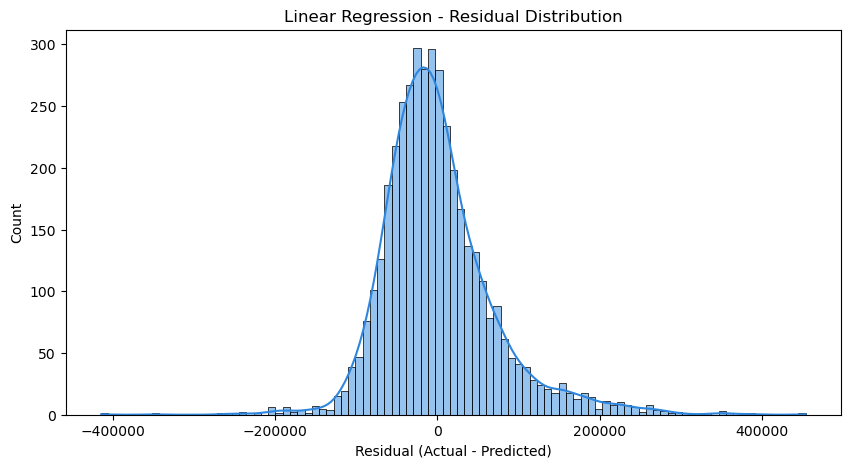

In [28]:
residuals_lr = y_test - y_pred_lr
plt.figure(figsize=(10,5))
sns.histplot(residuals_lr, kde=True, color='#2E86DE')
plt.title('Linear Regression - Residual Distribution')
plt.xlabel('Residual (Actual - Predicted)')
plt.show()

In [29]:
dt_model = Pipeline(steps=[('preprocessor', preprocessor),
                           ('model', DecisionTreeRegressor(random_state=42, max_depth=10))])
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
print("✅ Decision Tree Trained Successfully!")


✅ Decision Tree Trained Successfully!


In [30]:
mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
r2_dt = r2_score(y_test, y_pred_dt)
print("--- DECISION TREE RESULTS ---")
print(f"MAE  : {mae_dt:.2f}")
print(f"RMSE : {rmse_dt:.2f}")
print(f"R2 Score : {r2_dt:.4f}")
print(f"Accuracy : {r2_dt*100:.2f}%")


--- DECISION TREE RESULTS ---
MAE  : 40302.95
RMSE : 62017.66
R2 Score : 0.7065
Accuracy : 70.65%


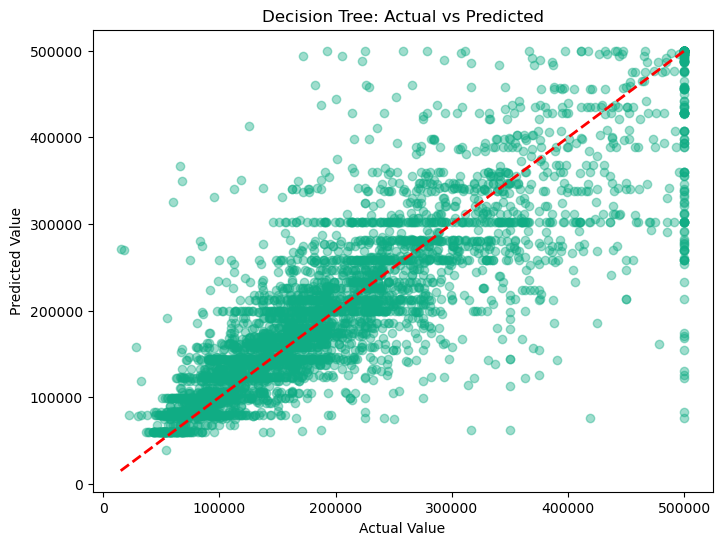

In [31]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_dt, alpha=0.4, color='#10AC84')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Decision Tree: Actual vs Predicted')
plt.xlabel('Actual Value')
plt.ylabel('Predicted Value')
plt.show()


In [32]:
rf_model = Pipeline(steps=[('preprocessor', preprocessor),
                           ('model', RandomForestRegressor(n_estimators=100, random_state=42))])
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
print("✅ Random Forest Trained Successfully!")

✅ Random Forest Trained Successfully!


In [33]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)
print("--- RANDOM FOREST RESULTS ---")
print(f"MAE  : {mae_rf:.2f}")
print(f"RMSE : {rmse_rf:.2f}")
print(f"R2 Score : {r2_rf:.4f}")
print(f"Accuracy : {r2_rf*100:.2f}%")


--- RANDOM FOREST RESULTS ---
MAE  : 31926.27
RMSE : 49833.73
R2 Score : 0.8105
Accuracy : 81.05%


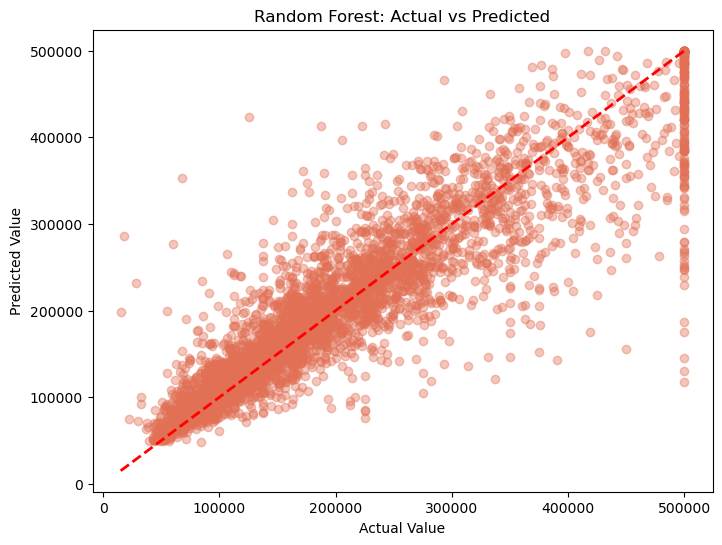

In [34]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_rf, alpha=0.4, color='#E17055')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Random Forest: Actual vs Predicted')
plt.xlabel('Actual Value')
plt.ylabel('Predicted Value')
plt.show()

In [35]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression','Decision Tree','Random Forest'],
    'MAE': [mae_lr, mae_dt, mae_rf],
    'RMSE': [rmse_lr, rmse_dt, rmse_rf],
    'R2 Score': [r2_lr, r2_dt, r2_rf],
    'Accuracy %': [r2_lr*100, r2_dt*100, r2_rf*100]
})
comparison.sort_values(by='R2 Score', ascending=False)

,Model,MAE,RMSE,R2 Score,Accuracy %
2,Random Forest,31926.269673,49833.732394,0.810487,81.048658
1,Decision Tree,40302.953832,62017.661039,0.706489,70.648932
0,Linear Regression,49645.492445,69127.038299,0.635339,63.533923


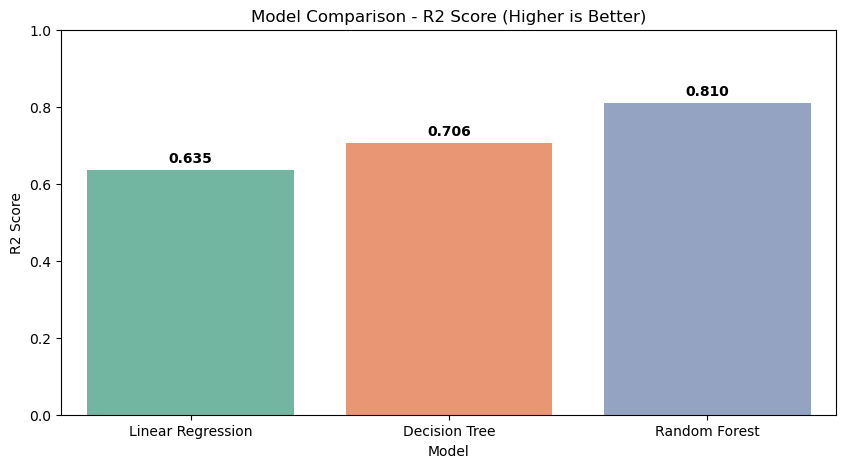

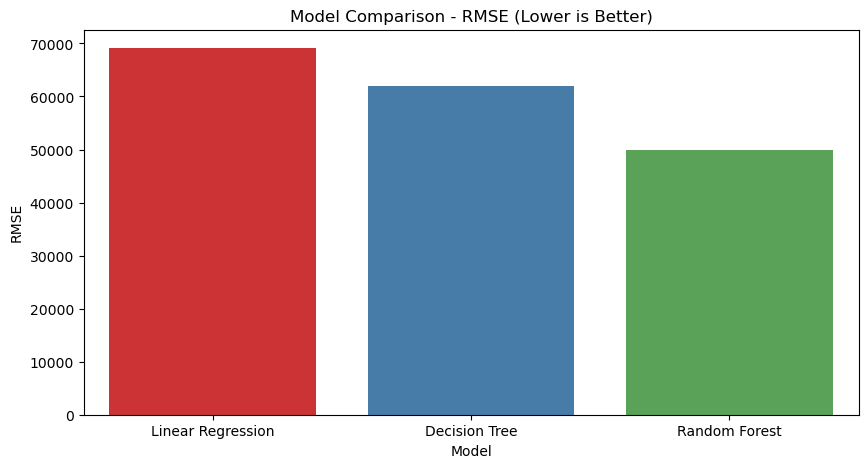

In [36]:
plt.figure(figsize=(10,5))
sns.barplot(data=comparison, x='Model', y='R2 Score', palette='Set2')
plt.title('Model Comparison - R2 Score (Higher is Better)')
plt.ylim(0,1)
for i, v in enumerate(comparison['R2 Score']):
    plt.text(i, v+0.02, f"{v:.3f}", ha='center', fontweight='bold')
plt.show()

# CELL 34: RMSE COMPARISON CHART
plt.figure(figsize=(10,5))
sns.barplot(data=comparison, x='Model', y='RMSE', palette='Set1')
plt.title('Model Comparison - RMSE (Lower is Better)')
plt.show()

In [37]:
sample_df = pd.DataFrame({
    'Actual': y_test.values[:10],
    'LR_Predicted': y_pred_lr[:10],
    'DT_Predicted': y_pred_dt[:10],
    'RF_Predicted': y_pred_rf[:10]
})
print("--- SAMPLE PREDICTIONS FOR 10 HOUSES ---")
sample_df.round(2)

--- SAMPLE PREDICTIONS FOR 10 HOUSES ---


,Actual,LR_Predicted,DT_Predicted,RF_Predicted
0,47700.0,36496.16,60288.39,53796.00
1,45800.0,137597.77,67636.36,70643.00
2,500001.0,293482.55,487771.41,460560.46
3,218600.0,281736.02,241440.91,257066.01
4,278000.0,263392.55,301878.36,229583.00
5,158700.0,182132.78,163056.38,161851.00
6,198200.0,275491.91,232531.68,223463.00
7,157500.0,207953.04,157421.37,166548.00
8,340000.0,261564.71,289081.25,255046.03
9,446600.0,415338.20,496147.06,478787.74


In [38]:
best = comparison.sort_values(by='R2 Score', ascending=False).iloc[0]
print(f"🏆 BEST MODEL: {best['Model']}")
print(f"R2 Score: {best['R2 Score']:.4f} | RMSE: {best['RMSE']:.2f}")
print("✅ CONCLUSION: Random Forest gives the highest R2 Score, so it predicts house prices most accurately.")
print("✅ TASK 4 COMPLETED!")

🏆 BEST MODEL: Random Forest
R2 Score: 0.8105 | RMSE: 49833.73
✅ CONCLUSION: Random Forest gives the highest R2 Score, so it predicts house prices most accurately.
✅ TASK 4 COMPLETED!
